In [23]:
import jax
print(jax.devices())  # confirm GPU is visible
import jcm

[CpuDevice(id=0)]


In [24]:
from jcm.model import Model
from jcm.terrain import TerrainData
from jcm.forcing import ForcingData
from importlib import resources
from jcm.physics.speedy.speedy_coords import get_speedy_coords

# Load the terrain and forcing data (interpolated to the default model grid)
data_dir = resources.files('jcm.data.bc.t30.clim')
coords = get_speedy_coords()
realistic_terrain = TerrainData.from_file(data_dir / 'terrain.nc', coords=coords)
realistic_forcing = ForcingData.from_file(data_dir / 'forcing.nc', coords=coords, align_mode='wrap_year')

/home/vpaidi/climatebench-env/lib/python3.11/site-packages/jcm/data/bc/interpolate.py:105: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([ds_interp, passthrough])
/home/vpaidi/climatebench-env/lib/python3.11/site-packages/jcm/data/bc/interpolate.py:53: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([dail

In [25]:
model = Model(
    coords=coords,
    terrain=realistic_terrain,
)

In [26]:
predictions = model.run(
    save_interval=5,
    total_time=30,
    output_averages=True,
    forcing=realistic_forcing,
)

In [27]:
pred_ds = predictions.to_xarray()
pred_ds

<xarray.Dataset> Size: 25MB
Dimensions:                                                 (time: 6, level: 8,
                                                             lon: 96, lat: 48,
                                                             bounds: 2)
Coordinates:
  * time                                                    (time) datetime64[ms] 48B ...
  * level                                                   (level) float64 64B ...
    hybrid_a_full                                           (level) float64 64B ...
    hybrid_b_full                                           (level) float64 64B ...
  * lon                                                     (lon) float64 768B ...
  * lat                                                     (lat) float64 384B ...
Dimensions without coordinates: bounds
Data variables: (12/77)
    u_wind                                                  (time, level, lon, lat) float32 885kB ...
    v_wind                                                  (time, level, lon, lat) float32 885kB ...
    temperature                                             (time, level, lon, lat) float32 885kB ...
    specific_humidity                                       (time, level, lon, lat) float32 885kB ...
    geopotential                                            (time, level, lon, lat) float32 885kB ...
    normalized_surface_pressure                             (time, lon, lat) float32 111kB ...
    ...                                                      ...
    surface_exchange.wind_v                                 (time, lon, lat) float32 111kB ...
    surface_exchange.air_density                            (time, lon, lat) float32 111kB ...
    surface_exchange.air_potential_temperature              (time, lon, lat) float32 111kB ...
    water_positivity_correction.specific_humidity_tendency  (time, level, lon, lat) float32 885kB ...
    water_positivity_correction.total_water_tendency        (time, level, lon, lat) float32 885kB ...
    time_bounds                                             (time, bounds) datetime64[ms] 96B ...
Attributes:
    Conventions:                      CF-1.11
    omitted_interval_mean_variables:  convection.iptop,shortwave_rad.compute_...
    jcm_prov_params:                  {"speedy_clouds.params.ablcl1": 12.0, "...
    jcm_prov_params_sha:              fd18f7eac5db

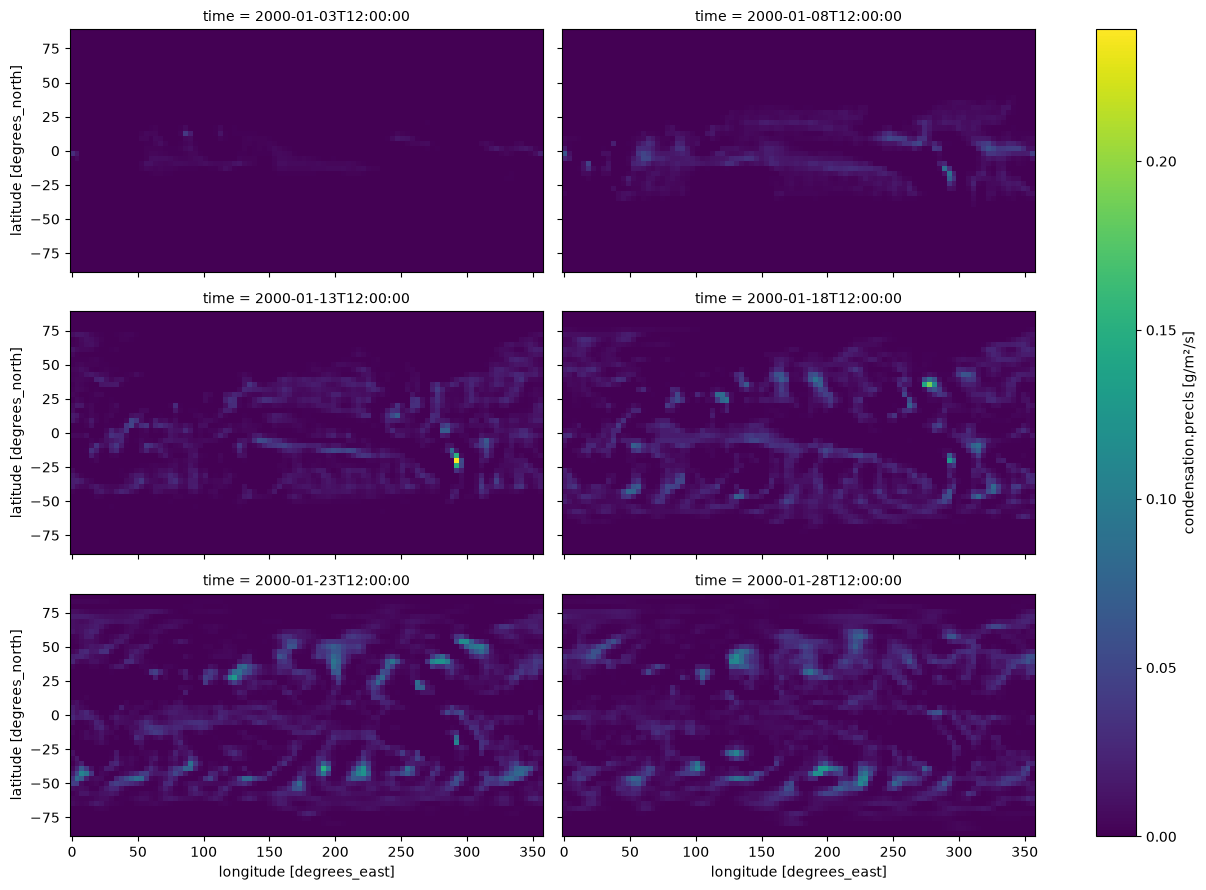

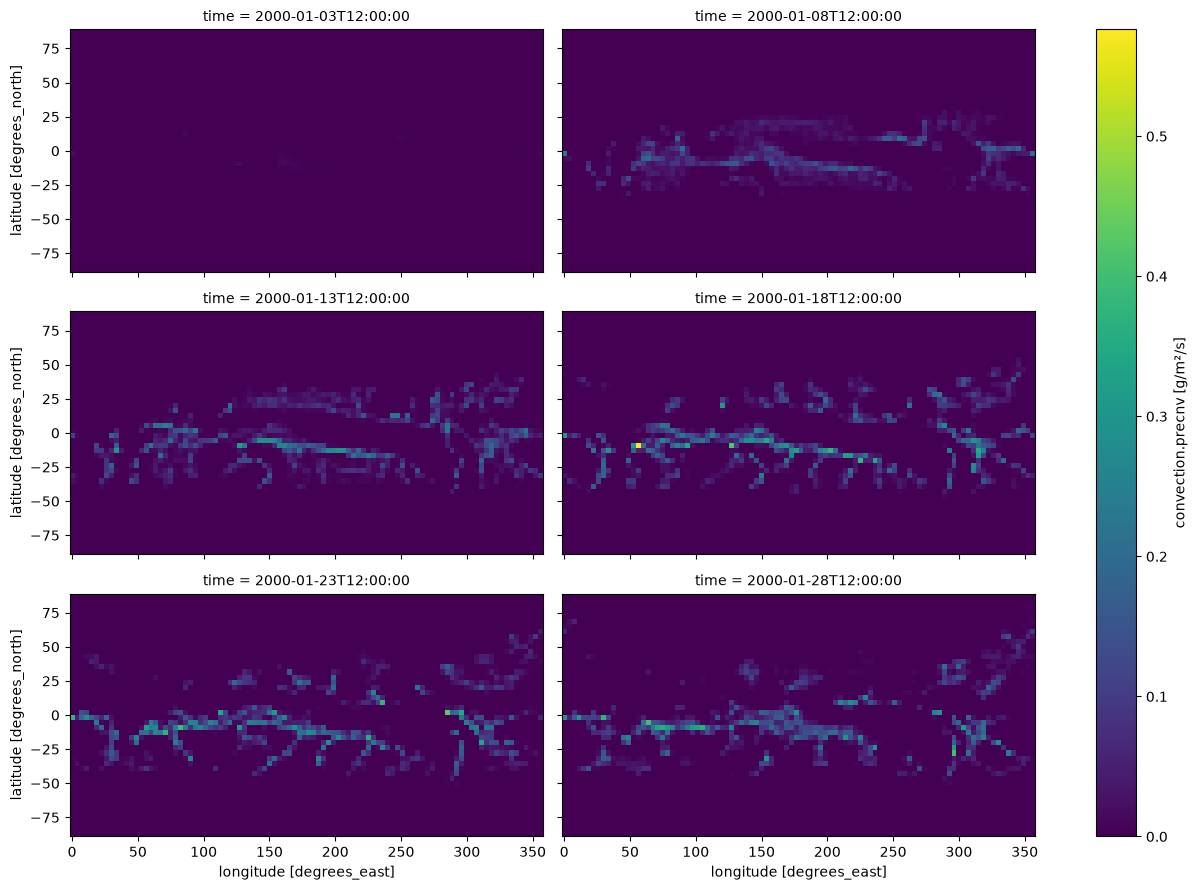

In [28]:
pred_ds['condensation.precls'].plot(x='lon', y='lat', col='time', col_wrap=2, aspect=2)
pred_ds['convection.precnv'].plot(x='lon', y='lat', col='time', col_wrap=2, aspect=2)

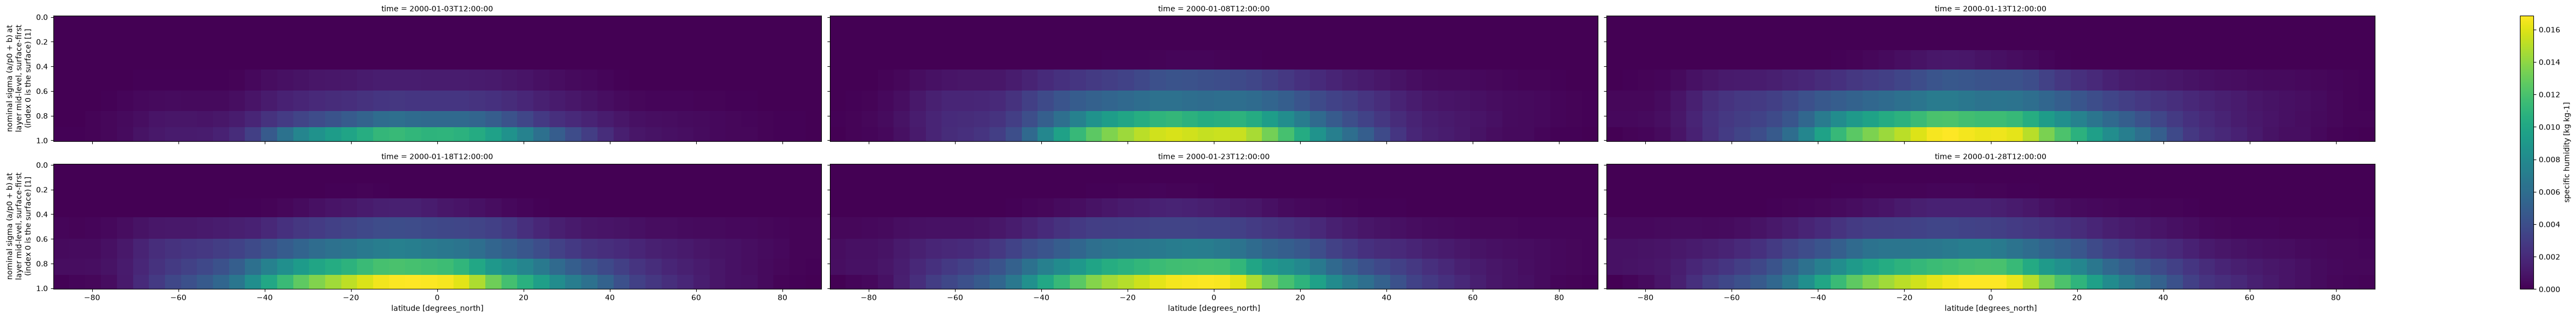

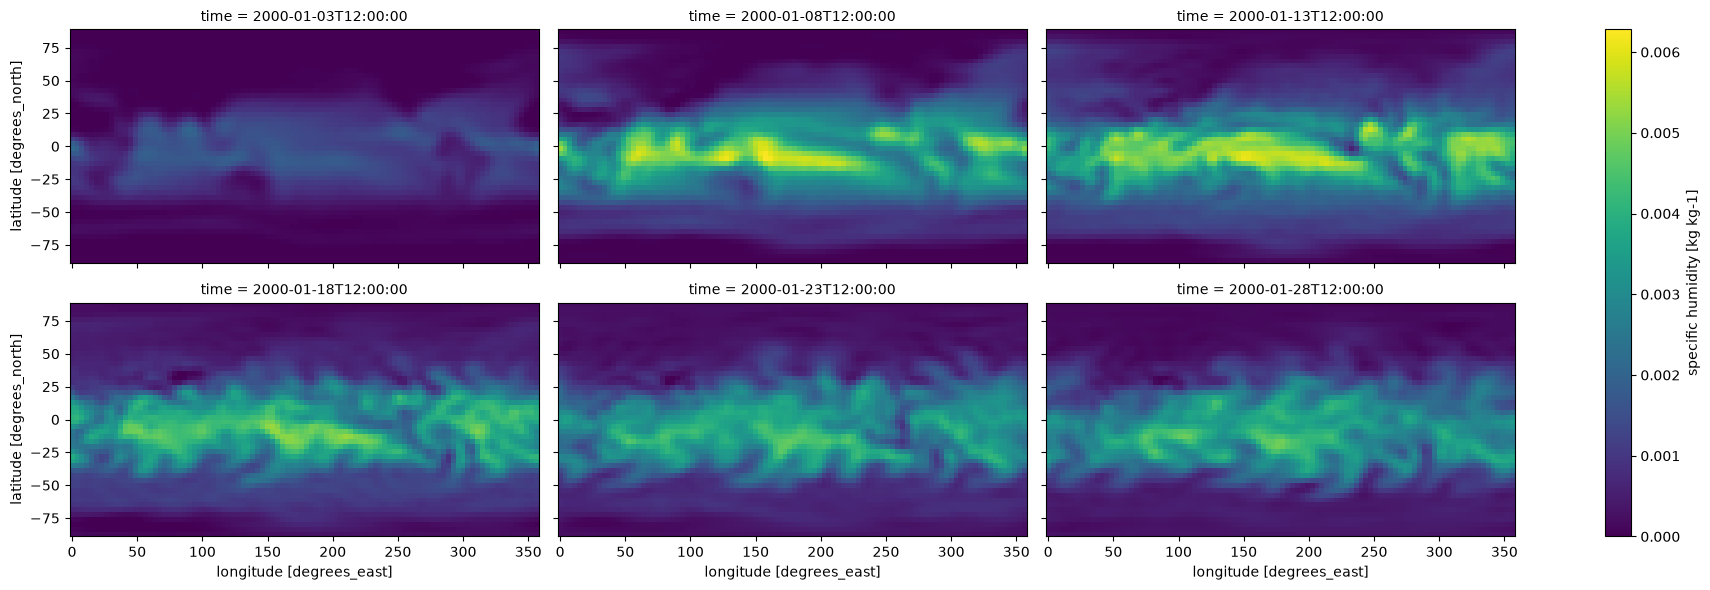

In [29]:
pred_ds['specific_humidity'].mean('lon').plot(x='lat', y='level', col='time', col_wrap=3, aspect=6, yincrease=False)
pred_ds['specific_humidity'].isel(level=3).plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)

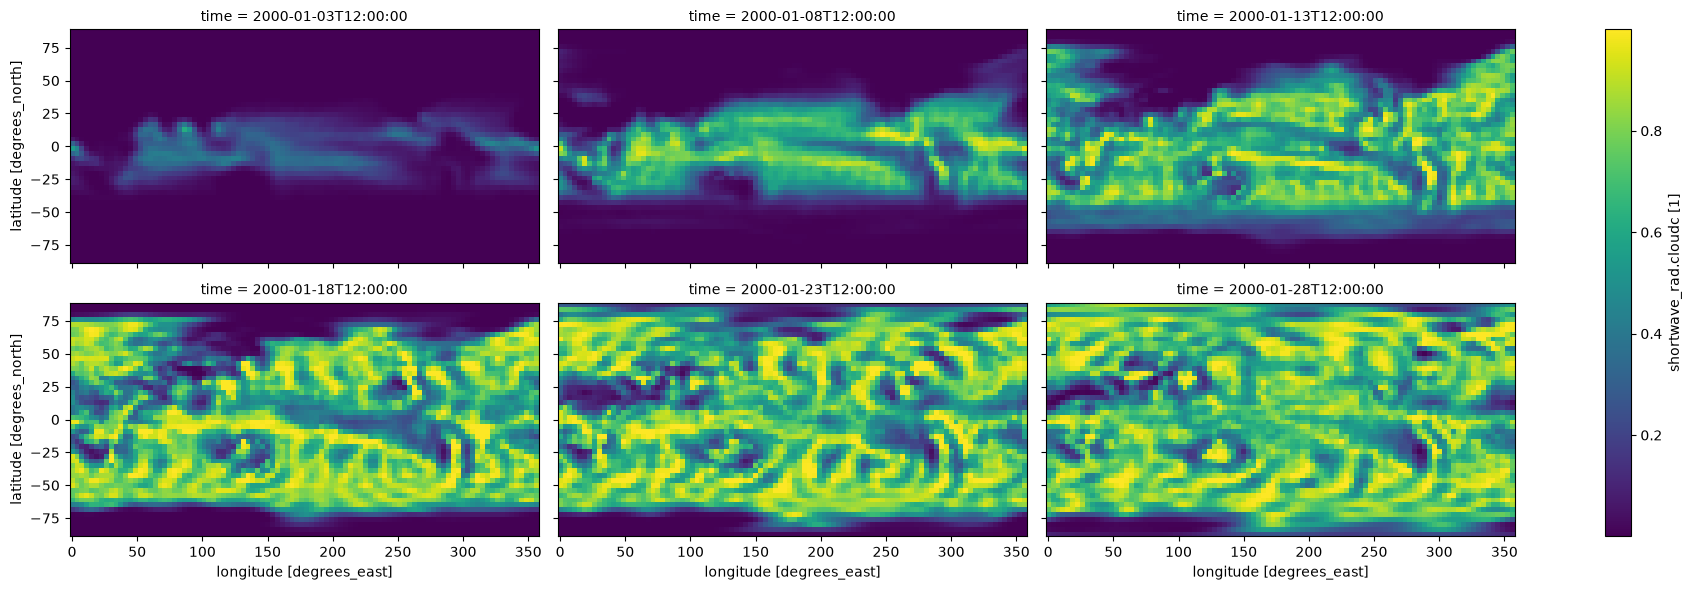

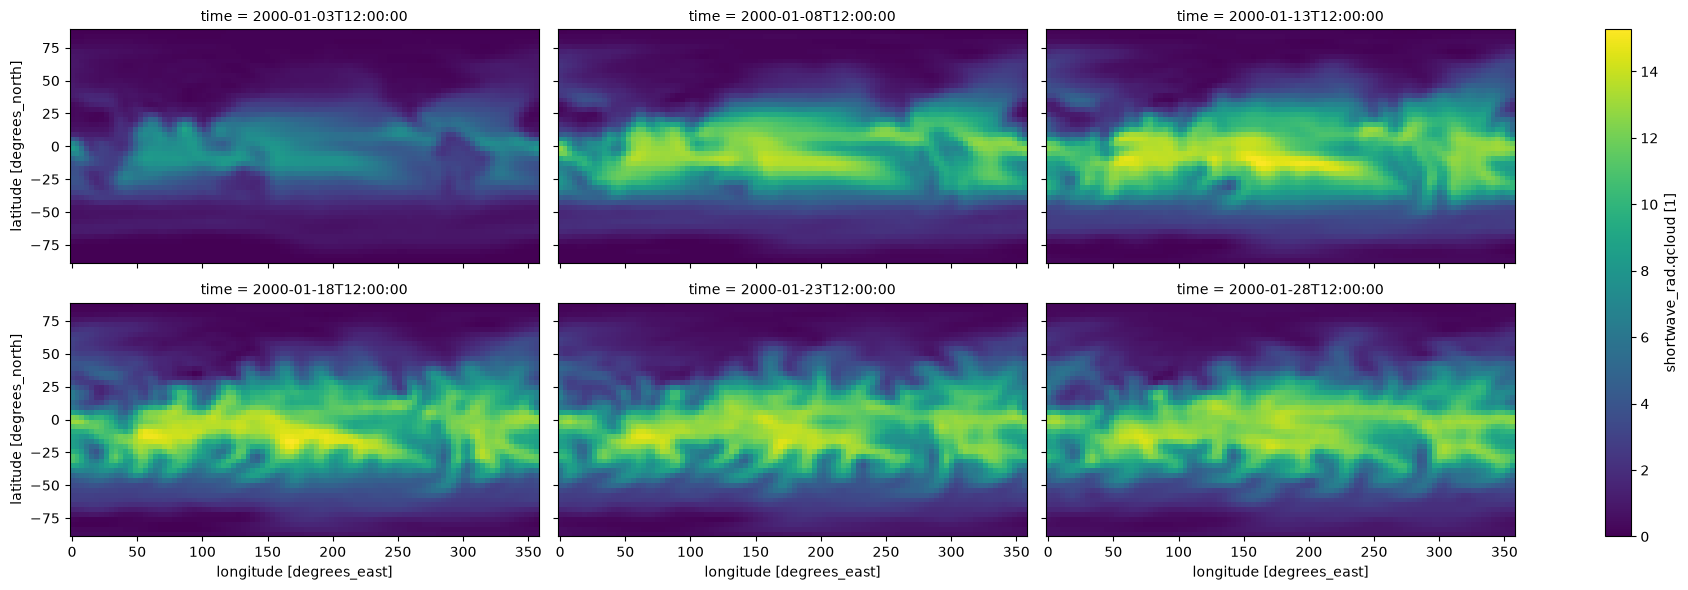

In [30]:
pred_ds['shortwave_rad.cloudc'].plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)
pred_ds['shortwave_rad.qcloud'].plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)

In [31]:
predictions = model.resume(
    total_time=30,
    output_averages=True,
    forcing=realistic_forcing,
)

In [32]:
import jax
import jax.numpy as jnp
import jax.tree_util as jtu
from jcm.physics.speedy.speedy_terms import speedy_physics
from jcm.physics.speedy.params import Parameters

# Key step - create a function that makes a model given parameters
def model_run_wrapper(params):
    model = Model(coords=coords, terrain=realistic_terrain, physics=speedy_physics(parameters=params))

    return model.run(save_interval=1, total_time=1, forcing=realistic_forcing, output_averages=True)

In [33]:
primal, vjp_fn = jax.vjp(model_run_wrapper, Parameters.default())

In [34]:
def create_cotangent(primal):
    cotangent = jtu.tree_map(jnp.zeros_like, primal)
    cotangent.physics['_shortwave_rad'].ftop = jtu.tree_map(jnp.ones_like, cotangent.physics['_shortwave_rad'].ftop)
    return cotangent

grad, = vjp_fn(create_cotangent(primal))

In [35]:
print(grad)

Parameters(convection=ConvectionParameters(psmin=0.0,
                                           trcnv=0.0,
                                           rhil=0.0,
                                           rhbl=0.0,
                                           entmax=0.0,
                                           smf=0.0,
                                           trigger_smoothing=0.0,
                                           precnv_smoothing=0.0),
           condensation=CondensationParameters(trlsc=0.0,
                                               rhlsc=0.0,
                                               drhlsc=0.0,
                                               rhblsc=0.0,
                                               cap_smoothing=0.0),
           shortwave_radiation=ShortwaveRadiationParameters(albcl=-30.428590774536133,
                                                            albcls=-495652.375,
                                                            absdry=958867.875,


In [36]:
# Define a tangent vector for JVP
params = Parameters.default()
tangent = Parameters.float_zeros()
tangent.mod_radcon.albsea = jnp.array(1.)

y, jvp_at_x = jax.jvp(model_run_wrapper, (params,), (tangent,))

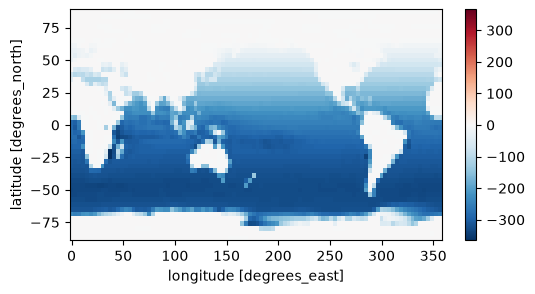

In [37]:
import xarray as xr
xr.DataArray(jvp_at_x.physics['_surface_flux'].hfluxn[0], dims=['lon', 'lat'],
                coords={'lat': pred_ds.lat, 'lon': pred_ds.lon}).plot(x='lon', y='lat', size=3, aspect=2)

In [38]:
print("JAX device:", jax.devices())

# import os
# os.environ["JAX_PLATFORM_NAME"] = "cpu"  # for use on ARM Macs

jax.config.update('jax_disable_jit', False) # disable if necessary for debugging
jax.config.update("jax_debug_infs", True) # watch for model blowup
jax.config.update("jax_debug_nans", False) # some physics fields might be nan

JAX device: [CpuDevice(id=0)]


In [39]:
"""
prefetch_data.py
================
Run this ONCE on a login node (which has internet) to populate the local
Hugging Face cache that the compute nodes read offline.
 
    conda activate climatebench
    python prefetch_data.py
"""
 
from jcm.data.remote import fetch
 
BUNDLES = [
    "bundles/t63/terrain.nc",
    "bundles/t63/forcing_pd.nc",
]
 
for b in BUNDLES:
    print(f"Fetching {b} …", flush=True)
    fetch(b)
    print(f"  OK")
 
print("\nAll bundles cached.  You can now run time_speedy.py on a compute node.")



Fetching bundles/t63/terrain.nc …


/home/vpaidi/climatebench-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  OK
Fetching bundles/t63/forcing_pd.nc …
  OK

All bundles cached.  You can now run time_speedy.py on a compute node.


In [40]:
"""
time_speedy.py
==============
Measures SPEEDY-T31L8 throughput under JCM, separating XLA compilation
time from actual run time, on whichever device JAX finds first.
 
Usage
-----
# CPU run:
python time_speedy.py
 
# GPU run (picks up the GPU automatically if jaxlib-cuda is installed):
JAX_PLATFORM_NAME=gpu python time_speedy.py
 
# Force CPU even when GPU is present:
JAX_PLATFORM_NAME=cpu python time_speedy.py
"""
 
from __future__ import annotations
 
import os
import sys
import time
import warnings
warnings.filterwarnings("ignore")
 
# ── 1. JAX must be imported before anything else touches the backend ──────────
import jax
import jax.numpy as jnp
 
DEVICE = jax.devices()[0]
BACKEND = jax.default_backend()          # 'cpu' or 'gpu'
print(f"\n{'='*60}")
print(f"  JAX backend : {BACKEND.upper()}")
print(f"  Device      : {DEVICE}")
print(f"{'='*60}\n")
 
# ── 2. Build the SPEEDY-T31L8 model via the JCM configuration system ─────────
#    speedy-t31 pulls terrain + forcing from HuggingFace, so we need internet.
#    If the bundles are already cached (login-node prefetch) this is instant.
 
from jcm import configurations
 
print("Loading speedy-t31 configuration …")
t0 = time.perf_counter()
exp = configurations.load("speedy-t31")          # downloads/verifies HF cache
t_load = time.perf_counter() - t0
print(f"  Config + forcing loaded in {t_load:.1f} s")
 
model   = exp.model
forcing = exp.forcing
 
# ── 3. WARM-UP / COMPILATION timing ──────────────────────────────────────────
#    Run a single 5-day chunk.  The first call traces + compiles the JIT;
#    subsequent calls reuse the compiled module.  We want *only* compilation,
#    so we record wall time of the first call then subtract the per-step cost
#    estimated from the second call.
 
WARMUP_DAYS   = 5     # long enough to be representative, short enough to not take forever
BENCH_DAYS    = 5     # second call: pure run time, no recompilation
YEAR_DAYS     = 365.0
 
print(f"\n── Warm-up / compilation run ({WARMUP_DAYS} days) ──────────────────────────")
t_w0 = time.perf_counter()
_ = model.run(
    forcing      = forcing,
    total_time   = WARMUP_DAYS,
    save_interval= WARMUP_DAYS,          # single snapshot → minimal I/O
    **{k: v for k, v in exp.run_kwargs.items()
       if k not in ("total_time", "save_interval", "forcing")},
)
jax.effects_barrier()                    # block until all device work is done
t_warmup = time.perf_counter() - t_w0
print(f"  Wall time (compile + run): {t_warmup:.2f} s")
 
# ── 4. BENCHMARK run (compiled kernel, no recompilation) ─────────────────────
print(f"\n── Benchmark run ({BENCH_DAYS} days, compiled) ──────────────────────────────")
t_b0 = time.perf_counter()
_ = model.run(
    forcing      = forcing,
    total_time   = BENCH_DAYS,
    save_interval= BENCH_DAYS,
    **{k: v for k, v in exp.run_kwargs.items()
       if k not in ("total_time", "save_interval", "forcing")},
)
jax.effects_barrier()
t_bench = time.perf_counter() - t_b0
print(f"  Wall time (run only):      {t_bench:.2f} s")
 
# ── 5. FULL-YEAR run (authoritative throughput number) ───────────────────────
#    Use chunked mode so we can also confirm the run stays healthy.
print(f"\n── Full 1-year run (365 days, compiled) ─────────────────────────────────")
t_yr0 = time.perf_counter()
preds = model.run(
    forcing      = forcing,
    total_time   = 365,
    save_interval= 5,                    # save every 5 days
    **{k: v for k, v in exp.run_kwargs.items()
       if k not in ("total_time", "save_interval", "forcing")},
)
jax.effects_barrier()
t_year = time.perf_counter() - t_yr0
print(f"  Wall time (1 year):        {t_year:.2f} s")
 
# ── 6. Derived metrics ────────────────────────────────────────────────────────
# Per-step cost from the benchmark call (15 min timestep → 8 steps/day)
DT_MIN       = 15
steps_per_day = 24 * 60 / DT_MIN           # 96
steps_bench   = BENCH_DAYS * steps_per_day
t_per_step    = t_bench / steps_bench       # seconds / model-step
 
# Compilation overhead: warmup − pure-run-of-same-length
t_compile     = t_warmup - t_bench          # rough estimate
 
# Throughput from the year run (cleanest number)
sypd          = YEAR_DAYS / t_year          # simulated days per wall-clock day
sypwch        = sypd * 24 / 24             # same thing normalised to 1 wall-clock day
years_per_hour= YEAR_DAYS / t_year / 24    # simulated years per wall-clock hour
 
print(f"""
╔══════════════════════════════════════════════════════════╗
║          SPEEDY-T31L8  ·  {BACKEND.upper():<6}  throughput report        ║
╠══════════════════════════════════════════════════════════╣
║  Config loaded          {t_load:>8.1f} s                       ║
║  XLA compilation (est.) {t_compile:>8.1f} s                       ║
║  Time per model step    {t_per_step*1000:>8.1f} ms  ({DT_MIN} min / step)      ║
║  1-year wall-clock time {t_year:>8.1f} s  ({t_year/60:.1f} min)             ║
║  ─────────────────────────────────────────────────────── ║
║  Simulated days / wall-clock day     {sypd:>8.1f}               ║
║  Simulated years / wall-clock hour   {years_per_hour:>8.2f}               ║
╚══════════════════════════════════════════════════════════╝
""")
 
# ── 7. Sanity-check: surface temperature stats ────────────────────────────────
try:
    ts = preds.surface_temperature if hasattr(preds, "surface_temperature") \
         else preds.diagnostics.get("surface_temperature")
    if ts is not None:
        ts_np = jnp.array(ts)
        print(f"Surface temp (K)  min={float(ts_np.min()):.1f}  "
              f"mean={float(ts_np.mean()):.1f}  max={float(ts_np.max()):.1f}")
except Exception:
    pass
 
print(f"\nDone.  Results above are for JAX backend = {BACKEND.upper()}.")


  JAX backend : CPU
  Device      : cpu:0

Loading speedy-t31 configuration …


forcing.ozone_file=auto on a sigma-vertical grid — the packaged and mirror ozone products are interpolated onto hybrid-level pressures and would be mapped level-for-level onto unrelated sigma levels. Falling back to the ANALYTIC ozone profile; supply an on-grid forcing.ozone_file (built for this vertical grid) for production radiation.


  Config + forcing loaded in 12.0 s

── Warm-up / compilation run (5 days) ──────────────────────────
  Wall time (compile + run): 30.88 s

── Benchmark run (5 days, compiled) ──────────────────────────────
  Wall time (run only):      0.15 s

── Full 1-year run (365 days, compiled) ─────────────────────────────────
  Wall time (1 year):        1674.96 s

╔══════════════════════════════════════════════════════════╗
║          SPEEDY-T31L8  ·  CPU     throughput report        ║
╠══════════════════════════════════════════════════════════╣
║  Config loaded              12.0 s                       ║
║  XLA compilation (est.)     30.7 s                       ║
║  Time per model step         0.3 ms  (15 min / step)      ║
║  1-year wall-clock time   1675.0 s  (27.9 min)             ║
║  ─────────────────────────────────────────────────────── ║
║  Simulated days / wall-clock day          0.2               ║
║  Simulated years / wall-clock hour       0.01               ║
╚════════════════════